# Convolutional Neural Networks (CNN) - Object Recognition 

A convolutional neural network (CNN) processes images represented as numerical pixel values. It applies filters (kernels) with weights learned during training. Each filter then extracts features from an input image or feature map to identify patterns.

The convolutional layer is the most critical layer in the CNN. Early layers focus on low-level features (edges, texture), while deeper layers combine them into more complex features and shapes.

Pooling layers reduce the size of feature maps by summarising the local regions. They retain useful information and discard the rest, which reduces computational cost but also loses some detail.

The resulting features support tasks such as image classification and object detection, such as object and face recognition. Depending on its design, a CNN can also produce feature vectors for comparing image similarity.


**Exercise Takeaway and Ethical Impact:**
4 out of 11 images were identified correctly (64% accuracy), indicating that the sampler is representative, as it matches 62.2% of the model's accuracy.

Two Frog-Frog examples with correct predictions of 0.45 and 0.85 show that the system has different levels of classification for the same category, which can be a result of different settings, lighting, and background, but budget the. The examples of incorrectly classified frog-deer are even more striking. The confidence score of 0.81 shows how a system learning from pixel-level patterns can produce misleadingly confident results. Confidence does not equal Correctness. Prediction can still be wrong. Especially when the frog cases are compared side by side by rank, the latter wins on the confidence score.

In this dataset, it is only a mislabeled form, but in the factual recognition context, the consequences of a misidentified person may have catastrophic outcomes, especially if the model is forced to take a 1 of 10 label decision and there is nothing in between. Human oversight is critical, but humans must also understand model limitations rather than blindly trusting confidence scores.


**TEST RESULT**

CORRECT
- **True: frog | Predicted: frog | Confidence: 0.45 Correct**
- **True: frog | Predicted: frog | Confidence: 0.85 Correct**
- True: airplane | Predicted: airplane | Confidence: 0.59 Correct
- True: truck | Predicted: truck | Confidence: 1.00 Correct
- True: horse | Predicted: horse | Confidence: 0.97 Correct
- True: truck | Predicted: truck | Confidence: 0.91 Correct
- True: ship | Predicted: ship | Confidence: 0.65 Correct

WRONG
- **True: frog | Predicted: deer | Confidence: 0.81 Wrong**
- True: dog | Predicted: cat | Confidence: 0.38 Wrong
- True: airplane | Predicted: ship | Confidence: 0.57 Wrong
- True: automobile | Predicted: dog | Confidence: 0.50 Wrong

# Imports

In [1]:
from numpy.random import seed
seed(888)

#from tensorflow import set_random_seed
#set_random_seed(4112)
import tensorflow
tensorflow.random.set_seed(112)

In [2]:
import os
import numpy as np
import itertools

import tensorflow as tf
import keras
from keras.datasets import cifar10 # importing the dataset

from keras.models import Sequential       #to define model/ layers
from keras.layers import Dense, Conv2D, MaxPool2D, Flatten   

from sklearn.metrics import confusion_matrix

# To Explore the images
from IPython.display import display
from keras.preprocessing.image import array_to_img

import tensorflow as tf
to_categorical = tf.keras.utils.to_categorical

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
import pandas as pd

We are using Tensorflow to power Keras

# Get the Dataset

CIFAR-10  is an established computer-vision dataset used for object recognition. It is a subset of the 80 million tiny images dataset and consists of 60,000 32x32 color images containing one of 10 object classes, with 6000 images per class. It was collected by Alex Krizhevsky, Vinod Nair, and Geoffrey Hinton.
The dataset is popularly used to train image classification models

In [4]:
# Getting the dataset as a Tuple

(x_train_all, y_train_all), (x_test, y_test) = cifar10.load_data()

# Constants

In [5]:
LABEL_NAMES = ['airplane', 'automobile','bird','cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Exploring the Data

Lets look at the first image in the dataset

In [6]:
x_train_all.shape

(50000, 32, 32, 3)

In [7]:
x_train_all[0]

array([[[ 59,  62,  63],
        [ 43,  46,  45],
        [ 50,  48,  43],
        ...,
        [158, 132, 108],
        [152, 125, 102],
        [148, 124, 103]],

       [[ 16,  20,  20],
        [  0,   0,   0],
        [ 18,   8,   0],
        ...,
        [123,  88,  55],
        [119,  83,  50],
        [122,  87,  57]],

       [[ 25,  24,  21],
        [ 16,   7,   0],
        [ 49,  27,   8],
        ...,
        [118,  84,  50],
        [120,  84,  50],
        [109,  73,  42]],

       ...,

       [[208, 170,  96],
        [201, 153,  34],
        [198, 161,  26],
        ...,
        [160, 133,  70],
        [ 56,  31,   7],
        [ 53,  34,  20]],

       [[180, 139,  96],
        [173, 123,  42],
        [186, 144,  30],
        ...,
        [184, 148,  94],
        [ 97,  62,  34],
        [ 83,  53,  34]],

       [[177, 144, 116],
        [168, 129,  94],
        [179, 142,  87],
        ...,
        [216, 184, 140],
        [151, 118,  84],
        [123,  92,  72]]

In [8]:
x_train_all[0].shape

(32, 32, 3)

#### Using ipython to display the image

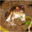

In [9]:
# To use the ipython display to view an image

pic = array_to_img(x_train_all[0])
display(pic)

#### Using Matplotlib to view the image

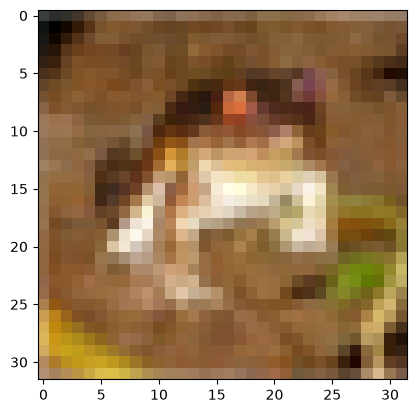

In [10]:
plt.imshow(x_train_all[0])


In [11]:
# To check the label 
y_train_all.shape

(50000, 1)

In [12]:
# Note that in the image above the index 1 corresponds to "Automobile" 
# we have a 2 dimension numpy array; that is why we also include " [0] "

y_train_all[0][0]

np.uint8(6)

In [13]:
# Using the lable names to get the actual names of classes

LABEL_NAMES[y_train_all[0][0]]

'frog'

### The shape of the image
    * 32, 32 is the weight and the height
    * 3 is the number of channels (These are the number of colors): Red, Green & Blue (RGB)
    
 * x_train_all.shape  >>> (50000, 32, 32, 3)
     * this means we have 50,000 entries | then 32x32  weight and height| 3 colors (RGB)

In [14]:
x_train_all.shape

(50000, 32, 32, 3)

In [15]:
number_of_images, x, y, c = x_train_all.shape
print(f'Number of images = {number_of_images} \t| width = {x} \t| height = {y} \t| channels = {c}')

Number of images = 50000 	| width = 32 	| height = 32 	| channels = 3


In [16]:
x_test.shape

(10000, 32, 32, 3)

# Preprocess Data

The preprocessing divides pixels value to 255 to scale them to 0-1, which support training converge. One one-hot encodes the labels to match the categorical cross-entropy loss.

#### * We need to preprocess our data so that it is easier to feed it to our neural network.
 

### Scalling both x_train and test


In [17]:
x_train_all =x_train_all / 255.0

In [18]:
x_test =  x_test / 255.0

In [19]:
y_test

array([[3],
       [8],
       [8],
       ...,
       [5],
       [1],
       [7]], shape=(10000, 1), dtype=uint8)

### Creating categorical encoding for the "y " data

In [20]:
# 10 >>> simply means we have 10 classes like we already know (creating the encoding for 10 classes)
y_cat_train_all = to_categorical(y_train_all,10)

In [21]:
# 10 >>> simply means we have 10 classes like we already know (creating the encoding for 10 classes)
y_cat_test = to_categorical(y_test,10)

In [22]:
y_cat_train_all

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

# Creating the Validation dataset

For small data we usually go with:
    * 60% for Training
    * 20% Validation
    * 20% Testing
    
Only the final selected model gets to see the testing data. This helps us to ensure that we have close to real data in real-world when the model is deployed. Only our best model gets to see our testing dataset. Because it will give us a realistic impression of how our model will do in the real world
___

However, if the dataset is enormous.:
    * 1% for is used for validation
    * 1% for is used for testing

In [23]:
VALIDATION_SIZE = 10000

In [24]:
# VALIDATION_SIZE = 10,000 as defined above 

x_val = x_train_all[:VALIDATION_SIZE]
y_val_cat = y_cat_train_all[:VALIDATION_SIZE]
x_val.shape

(10000, 32, 32, 3)

In [25]:
y_val_cat

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(10000, 10))

<b>NEXT:</b>
* We Create two NumPy arrays x_train and y_train that have the shape(40000, 3072) and (40000,1) respectively. 
* They will contain the last 40000 values from x_train_all and y_train_all respectively

In [26]:
x_train = x_train_all[VALIDATION_SIZE:]
y_cat_train= y_cat_train_all[VALIDATION_SIZE:]

In [27]:
x_train.shape

(40000, 32, 32, 3)

In [28]:
y_cat_train

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(40000, 10))

## NOTE:
 <h4>* <em>FILTERS: </em>
    Typical values for the number of filters can be determined by the data set's complexity. So essentially the larger the images, the more variety and the more classes you're trying to classify then the more filters you should have.</h4>
   <h4> * Most times people typically pick filter based on powers of 2, for example, 32. However, if you have more complex data like road signs etc. you should be starting with a higher filter value</h4>
   <h4>The default STRIDE value is 1 x 1 pixel</h4>

# BUILDING THE MODEL

1. FIRST SET OF LAYERS (CONVOLUTIONAL + POOLING LAYER): learns 32 low-level filters (edges, colour blobs) and halves the spatial size from 29×29 to 14×14. 

2. SECOND SET OF LAYERS: combines those into more complex patterns and reduces the size to 5×5. 

3. FLATTEN - it turns the 5×5×32 feature maps into an 800-element vector. 

4. DENSE - the dense layer (256 neurons) learns combinations of those features. 

5. SOFTMAX - The softmax output gives a probability for each of the 10 classes, and the highest one is the prediction. 

6. COMPILE - compile sets the Adam optimiser, the categorical cross-entropy loss and accuracy as the metric.

In [29]:
import warnings
warnings.filterwarnings('ignore', message='.*Do not pass an `input_shape`.*')

model = Sequential()

## ************* FIRST SET OF LAYERS *************************

# CONVOLUTIONAL LAYER
model.add(Conv2D(filters=32, kernel_size=(4,4),input_shape=(32, 32, 3), activation='relu',))
# POOLING LAYER
model.add(MaxPool2D(pool_size=(2, 2)))

## *************** SECOND SET OF LAYERS ***********************
#Since the shape of the data is 32 x 32 x 3 =3072 ... 
#We need to deal with this more complex structure by adding yet another convolutional layer

# *************CONVOLUTIONAL LAYER
model.add(Conv2D(filters=32, kernel_size=(4,4),input_shape=(32, 32, 3), activation='relu',))
# POOLING LAYER
model.add(MaxPool2D(pool_size=(2, 2)))

# FLATTEN IMAGES FROM 32 x 32 x 3 =3072 BEFORE FINAL LAYER
model.add(Flatten())

# 256 NEURONS IN DENSE HIDDEN LAYER (YOU CAN CHANGE THIS NUMBER OF NEURONS)
model.add(Dense(256, activation='relu'))

# LAST LAYER IS THE CLASSIFIER, THUS 10 POSSIBLE CLASSES
model.add(Dense(10, activation='softmax'))


model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

In [30]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 29, 29, 32)     │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 32)     │        16,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,610 (881.29 KB)

 Trainable params: 225,610 (881.29 KB)

 Non-trainable params: 0 (0.00 B)

### Adding Early stopping

In [31]:
from tensorflow.keras.callbacks import EarlyStopping

In [32]:
early_stop = EarlyStopping(monitor='val_loss',patience=2)

In [33]:
history = model.fit(x_train,y_cat_train,epochs=25,validation_data=(x_val,y_val_cat),callbacks=[early_stop])

Epoch 1/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 13s 10ms/step - accuracy: 0.4396 - loss: 1.5482 - val_accuracy: 0.5332 - val_loss: 1.2941
Epoch 2/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.5577 - loss: 1.2444 - val_accuracy: 0.5863 - val_loss: 1.1684
Epoch 3/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6124 - loss: 1.1001 - val_accuracy: 0.6140 - val_loss: 1.1070
Epoch 4/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6526 - loss: 0.9943 - val_accuracy: 0.6197 - val_loss: 1.0955
Epoch 5/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.6838 - loss: 0.9063 - val_accuracy: 0.6278 - val_loss: 1.0884
Epoch 6/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - accuracy: 0.7109 - loss: 0.8335 - val_accuracy: 0.6294 - val_loss: 1.1093
Epoch 7/25
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.7335 - loss: 0.7639 - val_accuracy: 0.6251 - val_loss: 1.1501


In [34]:
model.history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [35]:
metrics = pd.DataFrame(model.history.history)

In [36]:
metrics

,accuracy,loss,val_accuracy,val_loss
0,0.439625,1.548235,0.5332,1.294135
1,0.557700,1.244353,0.5863,1.168375
2,0.612375,1.100094,0.6140,1.106987
3,0.652625,0.994343,0.6197,1.095512
4,0.683775,0.906323,0.6278,1.088394
5,0.710900,0.833490,0.6294,1.109329
6,0.733500,0.763897,0.6251,1.150088


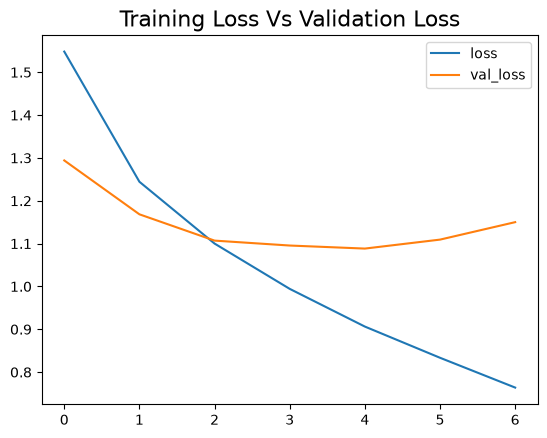

In [37]:
metrics[['loss', 'val_loss']].plot()
plt.title('Training Loss Vs Validation Loss', fontsize=16)
plt.show()

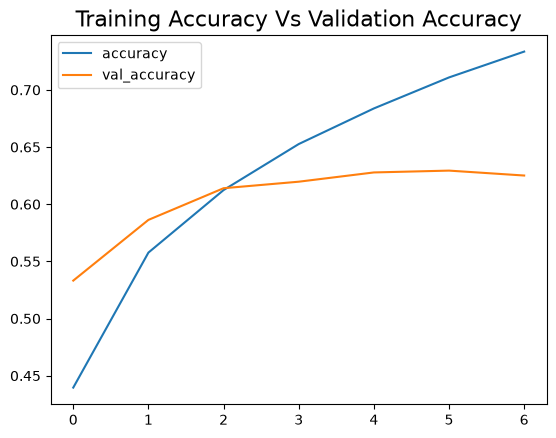

In [38]:
metrics[['accuracy', 'val_accuracy']].plot()
plt.title('Training Accuracy Vs Validation Accuracy', fontsize=16)
plt.show()

## Validating on Test Data

In [39]:
model.evaluate(x_test,y_cat_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6222 - loss: 1.1472


[1.1471511125564575, 0.6222000122070312]

In [40]:
print("test max:", x_test.max())
print(model.evaluate(x_test, to_categorical(y_test, 10), verbose=0))

test max: 1.0
[1.1471511125564575, 0.6222000122070312]


## Classification Report and Confusion Matrix

In [41]:
from sklearn.metrics import classification_report, confusion_matrix

In [42]:
#predictions = model.predict_classes(x_test)
predictions = np.argmax(model.predict(x_test), axis=-1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [43]:
print(classification_report(y_test,predictions))

              precision    recall  f1-score   support

           0       0.77      0.58      0.66      1000
           1       0.83      0.68      0.75      1000
           2       0.52      0.46      0.49      1000
           3       0.38      0.62      0.47      1000
           4       0.52      0.60      0.56      1000
           5       0.56      0.47      0.51      1000
           6       0.69      0.69      0.69      1000
           7       0.72      0.65      0.68      1000
           8       0.79      0.72      0.75      1000
           9       0.68      0.77      0.72      1000

    accuracy                           0.62     10000
   macro avg       0.65      0.62      0.63     10000
weighted avg       0.65      0.62      0.63     10000



In [44]:
confusion_matrix(y_test,predictions)

array([[577,  21,  88,  51,  61,  25,  18,  12,  73,  74],
       [ 24, 676,  13,  35,   8,  17,  25,   9,  45, 148],
       [ 43,   6, 461, 152, 151,  63,  74,  35,   8,   7],
       [  6,   5,  58, 617,  79, 117,  62,  33,   3,  20],
       [ 10,   2,  70, 117, 602,  34,  68,  73,  15,   9],
       [  6,   3,  64, 307,  61, 469,  20,  55,   5,  10],
       [  1,   4,  43, 146,  61,  33, 687,  15,   5,   5],
       [  7,   1,  39, 100, 106,  57,  10, 649,   6,  25],
       [ 63,  29,  27,  53,  19,  13,  10,   6, 718,  62],
       [ 12,  64,  16,  55,   9,  15,  15,  18,  30, 766]])

# Predicting on single image

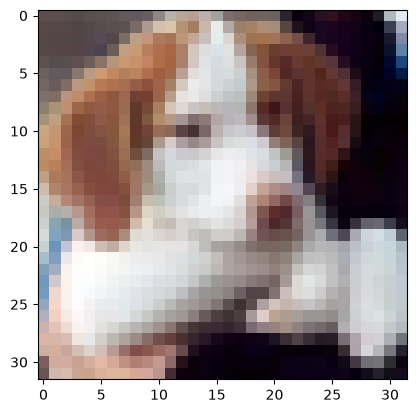

In [45]:
plt.imshow(x_test[16])

In [46]:
my_image = x_test[16]

In [47]:
# SHAPE --> (num_images,width,height,color_channels)
np.argmax(model.predict(my_image.reshape(1, 32, 32, 3)), axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


array([5])

In [48]:
LABEL_NAMES[y_test[16][0]]

'dog'

# TESTING

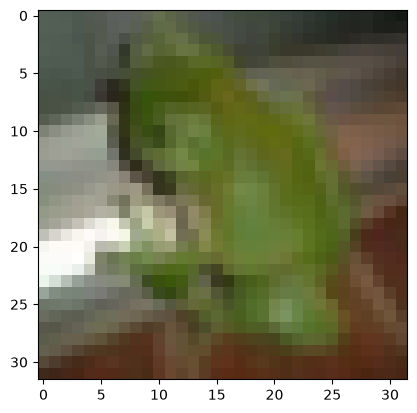

In [69]:
# TESTING

index = 7
LABEL_NAMES = ['airplane', 'automobile','bird','cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

my_image = x_test[index]
plt.imshow(my_image)
plt.show()

In [70]:
probs = model.predict(my_image.reshape(1,32,32,3), verbose=0)[0]
pred = np.argmax(probs)
true = y_test[index][0]

print(f"True: {LABEL_NAMES[true]} | Predicted: {LABEL_NAMES[pred]} | Confidence: {probs[pred]:.2f}")
print("Correct" if pred == true else "Wrong")

True: frog | Predicted: frog | Confidence: 0.85
Correct
